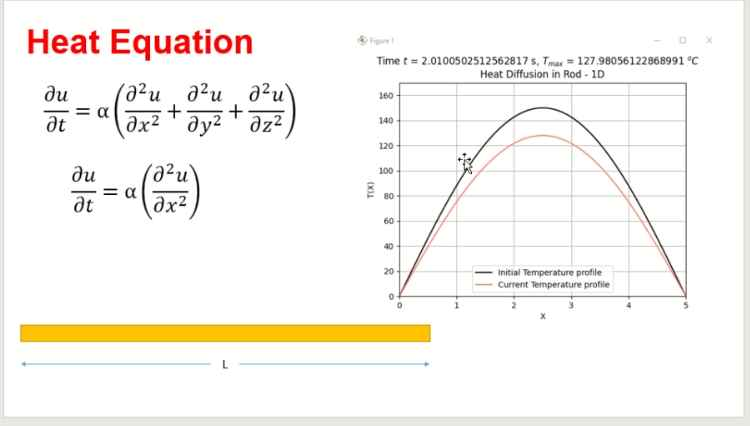

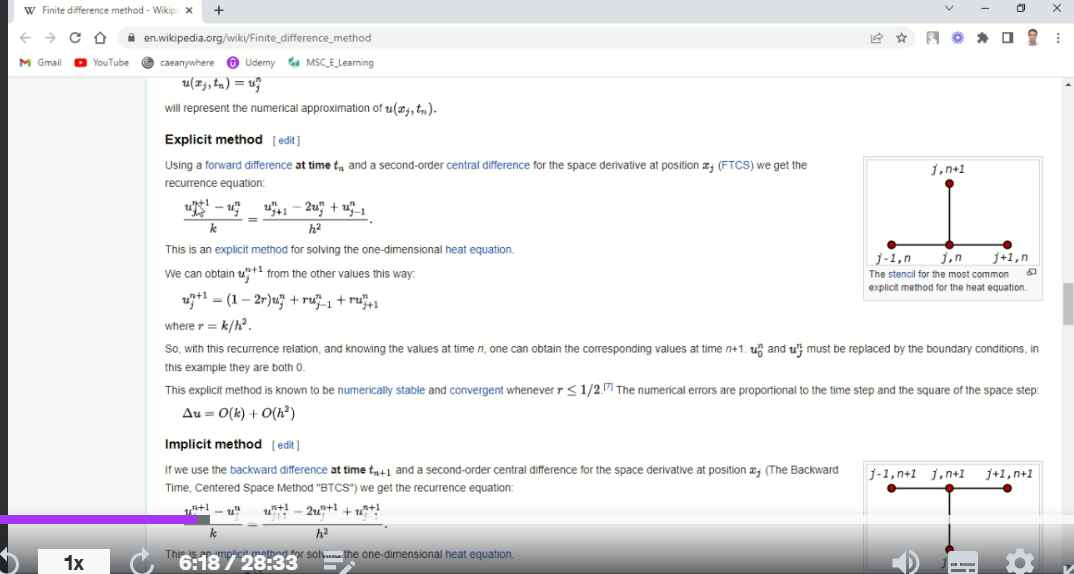

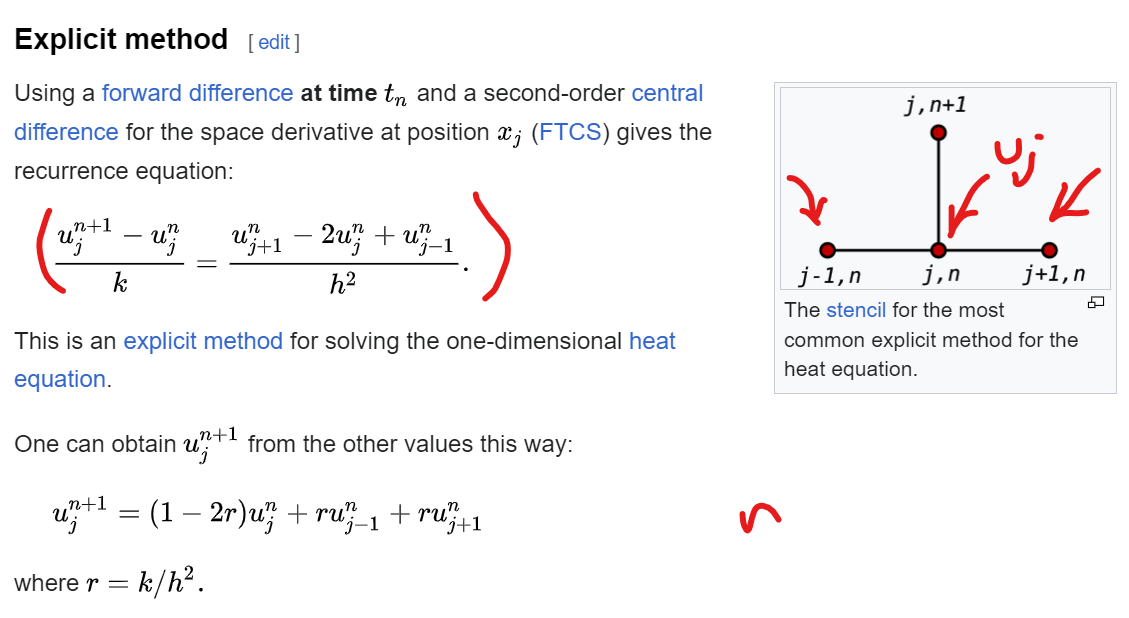

In [ ]:
#SEC7_Thermal System One Dimensional Heat.ipynb
#39. Program - 3 - One Dimensional Heat Equation with Animated Plot

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

L = 5  		# lenght of the rod
nx = 150  	# number of points on the length
T = 10  	# total time of the simulation
nt = 200 	# number of time steps

x = np.linspace(0,L,nx)

k = 0.2		# heat constant
h = L / (nx - 1)

dudt = []

def diff_fun(u,t):

	dudt = np.ones(x.shape)

	dudt[0] = 0
	dudt[-1] = 0

	for i in range(1, nx-1):
		dudt[i] = k * (u[i + 1] - 2*u[i] + u[i - 1]) / h**2

	return dudt
t_max = 150

in_temp = t_max*np.ones(x.shape)*np.sin(np.pi*x/L)

tspan = np.linspace(0.0, T, nt)
sol = odeint(diff_fun, in_temp, tspan)

for i in range(len(tspan)):

    plt.clf()
    plt.plot(x, sol[0],color='black',label='Initial Temperature profile')
    plt.plot(x, sol[i],color='salmon',label='Current Temperature profile')
    heading = 'Time $t$ = '+str(tspan[i])+' s, $T_{max}$ = '+str(np.amax(sol[i]))+' $^o C$'
    plt.suptitle(heading)
    plt.title('Heat Diffusion in Rod - 1D')
    plt.xlim(0,L)
    plt.ylim(0,t_max+20)
    plt.grid()
    plt.xlabel('X')
    plt.ylabel('T(X)')
    #plt.title('t = {0}'.format(tspan[i]))
    plt.legend()
    plt.pause(0.01)


#39. Program - 3 - One Dimensional Heat Equation with Animated Plot


import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from numpy import sin,pi


L = 5  		# lenght of the rod
nx = 150  	# number of points on the length
Ts = 10  	# total time of the simulation
nt = 200 	# number of time steps
k = 0.2		# heat constant

X = np.linspace(0,L,nx) #rod discretization into 150 points  `-------------`
print("X\n",X.shape,"\n",X)
h = L / (nx - 1) # interval between points

DuDt = []   # empty array
#DuDt = np.ones(x.shape) #matrix  with  ones with same shape as X =150
#print(DuDt) # matrix  with  ones

def diff_fun(u,t): # 'u' is heat ,'t' is time
    DuDt = np.zeros(X.shape)
    print("DuDt\n",DuDt,"\n", DuDt.shape)

    DuDt[0] = 0  # start point is Zero temperature
    DuDt[-1] = 0  # end  point is Zero temperature
#https://en.wikipedia.org/wiki/Finite_difference_method  Explicit method

    for j in range(1, nx-1):
        DuDt[j] = k * (u[j + 1] - 2*u[j] + u[j - 1]) / h**2 # from  picture
    print("DuDt\n",DuDt,"\n", DuDt.shape)
    return DuDt

Max_Temp=150 # initial temperature

initial_Temp =np.ones(X.shape)*Max_Temp*sin(pi*X/L)
print("initial_Temp \n",initial_Temp," \n", initial_Temp.shape)

#plt.plot(X,initial_Temp)  # for  viewing Temperature  profile
#plt.show()   # for  viewing Temperature  profile

tspan=np.linspace(0,Ts,nt)
print("tspan\n",tspan,"\n", tspan.shape)

Solution = odeint(diff_fun, initial_Temp, tspan)

print("Solution\n",Solution,"\n", Solution.shape)

for i in range(len(tspan)):
    plt.clf()
    plt.plot(X,initial_Temp)
    plt.clf()
    plt.plot(X,Solution[0],color='Red',label="initial temperature")
    plt.plot(X,Solution[i],color='Blue',label="Current temperature ")
    heading = 'Time $t$ = '+str(tspan[i])+' s, $T_{max}$ = '+str(np.amax(Solution[i]))+' $^o C$'
    heading2= 'Time step  $t$ = '+str(i)

    plt.suptitle(heading)

    plt.title('Heat Diffusion in Rod - 1D')
    plt.title(heading2,fontsize=5, loc="right")
    plt.xlim(0,L)
    plt.ylim(0,Max_Temp+20)
    plt.grid()
    plt.xlabel('X')
    plt.ylabel('T(X)')
    plt.legend()
    plt.pause(0.01)